# Phase 3: polar teacher, a staged fine-tune policy



## 1. Setup 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, shutil, subprocess, json, glob, re, time
DRIVE_ROOT = "/content/drive/MyDrive/spirob_vision"
OUT   = f"{DRIVE_ROOT}/polar_teacher"
WS    = f"{DRIVE_ROOT}/workspace_map"
SIR_CKPT = f"{DRIVE_ROOT}/sir_stage1/model_499.pt"
REPO  = "/content/spirob-polar"
BRANCH = "origin/research/s2-spawn-randomization"
LOGS  = f"{REPO}/logs/rsl_rl/spirob_minimal"
NUM_ENVS = 256            # T4; on a G4 you can use 512
os.makedirs(OUT, exist_ok=True)
if shutil.which("uv") is None:
    subprocess.run("curl -LsSf https://astral.sh/uv/install.sh | sh", shell=True, check=True)
    os.environ["PATH"] = f"/root/.local/bin:{os.environ['PATH']}"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "https://github.com/YADlin/spirob-mjlab", REPO], check=True)
os.chdir(REPO)
subprocess.run(["git", "fetch", "origin"], check=True)
subprocess.run(["git", "checkout", "-B", "polar-work", BRANCH], check=True)
subprocess.run(["uv", "sync"], check=True)
print(subprocess.run(["uv", "run", "python", "-c", "import torch; print('GPU:', torch.cuda.get_device_name(0))"],
                     capture_output=True, text=True).stdout)
print("sir checkpoint:", os.path.isfile(SIR_CKPT), os.path.getsize(SIR_CKPT) if os.path.isfile(SIR_CKPT) else "")
print("stages already on Drive:", sorted(os.listdir(OUT)))

## 2. scripts (polar tasks, check/eval, train wrapper)

In [ ]:
%%writefile /content/spirob-polar/tools/polar_tasks.py

from mjlab.managers.event_manager import EventTermCfg
from mjlab.managers.metrics_manager import MetricsTermCfg
from mjlab.tasks.registry import register_mjlab_task

import spirob_mjlab  # noqa: F401  (registers sir's tasks)
from spirob_mjlab import mdp
from spirob_mjlab.entities import movable_pedestal_cfg
from spirob_mjlab.env_cfgs import spirob_egg_to_bucket_stage1_env_cfg
from spirob_mjlab.rl_cfg import Stage2FineTuneRunner, spirob_ppo_runner_cfg

RADIUS_M = (0.120, 0.200)
POLAR_TASKS = {
    "Mjlab-SpiRob-Polar-Right": (RADIUS_M, (30.0, 80.0)),
    "Mjlab-SpiRob-Polar-Left": (RADIUS_M, (100.0, 150.0)),
    "Mjlab-SpiRob-Polar-Wide": (RADIUS_M, (30.0, 150.0)),
}


def polar_env_cfg(radius_range_m, angle_range_deg, play=False):
    cfg = spirob_egg_to_bucket_stage1_env_cfg(play=play)
    if play:
        cfg.episode_length_s = 8.0
    cfg.scene.entities["pedestal"] = movable_pedestal_cfg()
    cfg.events["stage2_egg_pedestal_spawn"] = EventTermCfg(
        func=mdp.reset_stage2_sector_egg_and_pedestal,
        mode="reset",
        params={
            "radius_range_m": radius_range_m,
            "angle_range_deg": angle_range_deg,
            # 1 x 1 strata: a wide sector crosses the robot/bucket exclusion zones,
            # and fully-excluded strata would make stratified sampling fail
            "radial_strata": 1,
            "angular_strata": 1,
            "schedule_length": 10,
            "nominal_slots": 1,
            "retention_slots": 3,
            "max_resample_attempts": 256,
            "min_robot_centerline_clearance": 0.038,
            "min_bucket_center_clearance": 0.055,
        },
    )
    cfg.metrics = {
        "spawn_radius_mm": MetricsTermCfg(func=mdp.stage2_spawn_radius_mm, reduce="last"),
        "spawn_angle_deg": MetricsTermCfg(func=mdp.stage2_spawn_angle_deg, reduce="last"),
        "spawn_is_sector": MetricsTermCfg(func=mdp.stage2_spawn_is_sector, reduce="last"),
        "spawn_rejection_count": MetricsTermCfg(func=mdp.stage2_spawn_rejection_count, reduce="last"),
    }
    return cfg


for _task_id, (_r, _th) in POLAR_TASKS.items():
    register_mjlab_task(
        task_id=_task_id,
        env_cfg=polar_env_cfg(_r, _th, play=False),
        play_env_cfg=polar_env_cfg(_r, _th, play=True),
        rl_cfg=spirob_ppo_runner_cfg(stage2=True),
        runner_cls=Stage2FineTuneRunner,
    )

In [ ]:
%%writefile /content/spirob-polar/tools/polar_check.py

import sys, os, json, time, argparse, math
from dataclasses import asdict
sys.path.insert(0, "/content/spirob-polar/tools")
import numpy as np
import torch
from tensordict import TensorDict
import polar_tasks  # noqa: F401  (registers the polar tasks)
from mjlab.envs import ManagerBasedRlEnv
from mjlab.rl import MjlabOnPolicyRunner, RslRlVecEnvWrapper
from mjlab.tasks.registry import load_env_cfg, load_rl_cfg, load_runner_cls

ap = argparse.ArgumentParser()
ap.add_argument("--mode", choices=["spawns", "eval"], required=True)
ap.add_argument("--task", default="Mjlab-SpiRob-Polar-Wide")
ap.add_argument("--out", required=True)
ap.add_argument("--ws", default="", help="workspace_map folder, for the background map")
ap.add_argument("--num_envs", type=int, default=512)
ap.add_argument("--rounds", type=int, default=3)
ap.add_argument("--checkpoint", default="")
ap.add_argument("--label", default="policy")
a = ap.parse_args()
os.makedirs(a.out, exist_ok=True)
DEV = "cuda:0"
BUCKET = (-0.05, 0.15)
GROUP = {0: "nominal", 1: "retention", 2: "sector"}


def make_env():
    cfg = load_env_cfg(a.task, play=False)
    cfg.scene.num_envs = a.num_envs
    cfg.auto_reset = False
    cfg.seed = 1001
    cfg.observations["actor"].enable_corruption = False
    cfg.observations["critic"].enable_corruption = False
    env = ManagerBasedRlEnv(cfg=cfg, device=DEV)
    vec = RslRlVecEnvWrapper(env, clip_actions=load_rl_cfg(a.task).clip_actions)
    return env, vec


def spawn_info(env):
    egg = env.scene["egg"].data.root_link_pos_w - env.scene.env_origins
    grp = getattr(env, "_stage2_spawn_group", torch.full((env.num_envs,), -1, device=DEV))
    return egg[:, :2].clone(), egg[:, 2].clone(), grp.clone()


def flags(env):
    tm = env.termination_manager
    g = lambda n: tm.get_term(n).bool()
    return g("success_egg_inside_bucket"), g("egg_fell") | g("egg_oob"), g("nan_state")


def run_round(env, vec, policy, steps):
    """One synchronous batch: every env runs one episode; finished envs are reset and masked."""
    vec.reset()
    xy, z0, grp = spawn_info(env)
    # same method as sir's evaluators: build the first observation after the reset
    obs = TensorDict(env.observation_manager.compute(update_history=True), batch_size=[env.num_envs])
    N = env.num_envs
    done = torch.zeros(N, dtype=torch.bool, device=DEV)
    succ, fell, crash = done.clone(), done.clone(), done.clone()
    min_z = z0.clone()
    for t in range(steps):
        with torch.no_grad():
            act = policy(obs) if policy is not None else torch.zeros((N, 2), device=DEV)
        obs, _, dones, _ = vec.step(act)
        ez = env.scene["egg"].data.root_link_pos_w[:, 2]
        min_z = torch.where(done, min_z, torch.minimum(min_z, ez))
        s, f, n = flags(env)
        new = ~done & (s | f | n)
        succ |= new & s; fell |= new & f & ~s; crash |= new & n & ~s
        done |= new
        if bool(done.all()):
            break
        ended = torch.nonzero(dones.bool()).flatten()
        if len(ended):
            env.reset(env_ids=ended)
    return dict(xy=xy.cpu().numpy(), z0=z0.cpu().numpy(), group=grp.cpu().numpy(),
                success=succ.cpu().numpy(), fell=fell.cpu().numpy(), crash=crash.cpu().numpy(),
                drop_mm=((z0 - min_z) * 1000).cpu().numpy())


def background(ax):
    import matplotlib.pyplot as plt
    LIM, CELL = 0.35, 0.005
    NC = int(round(2 * LIM / CELL))
    grid = np.zeros(NC * NC)
    for f in ("hold.npz", "random.npz"):
        p = os.path.join(a.ws, f)
        if a.ws and os.path.isfile(p):
            grid += np.load(p)["body"]
    if grid.any():
        ax.imshow(np.log1p(grid.reshape(NC, NC)), origin="lower", extent=[-LIM, LIM, -LIM, LIM],
                  cmap="Greys", alpha=0.6)
    for rr in (0.12, 0.20):
        ax.add_patch(plt.Circle((0, 0), rr, fill=False, ls="--", lw=0.8, color="tab:blue"))
    ax.add_patch(plt.Circle(BUCKET, 0.055, fill=False, lw=1, color="red"))
    ax.axvspan(-0.038, 0.038, color="orange", alpha=0.12)
    ax.plot(*BUCKET, "s", color="red", label="bucket (+55 mm exclusion)")
    ax.plot(0, 0, "k+", ms=10, label="robot base")
    ax.set_xlim(-0.25, 0.25); ax.set_ylim(-0.02, 0.26); ax.set_aspect("equal")
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")


def polar(xy):
    return np.hypot(xy[:, 0], xy[:, 1]) * 1000, np.degrees(np.arctan2(xy[:, 1], xy[:, 0]))


import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

if a.mode == "spawns":
    env, vec = make_env()
    rows = [run_round(env, vec, None, 150) for _ in range(a.rounds)]   # robot held still, 1.5 s
    R = {k: np.concatenate([r[k] for r in rows]) for k in rows[0]}
    r_mm, th = polar(R["xy"])
    stable = (~R["fell"]) & (~R["crash"]) & (R["drop_mm"] < 5)
    print(f"{a.task}: {len(r_mm)} spawns")
    for g, name in GROUP.items():
        m = R["group"] == g
        if m.any():
            print(f"  {name:9s}: {m.sum():5d} spawns | r {r_mm[m].min():5.0f}-{r_mm[m].max():5.0f} mm | "
                  f"theta {th[m].min():5.1f}-{th[m].max():5.1f} deg | egg stays on pedestal {stable[m].mean():.0%}")
    bd = np.hypot(R["xy"][:, 0] - BUCKET[0], R["xy"][:, 1] - BUCKET[1]) * 1000
    print(f"  closest spawn to bucket centre: {bd.min():.0f} mm (must be >= 55) | "
          f"closest to robot centreline: {np.abs(R['xy'][:, 0]).min() * 1000:.0f} mm (must be >= 38)")
    print(f"  ALL spawns stable: {bool(stable.all())}  ({(~stable).sum()} unstable)")
    fig, ax = plt.subplots(figsize=(8, 5))
    background(ax)
    ax.scatter(R["xy"][stable, 0], R["xy"][stable, 1], s=4, c="tab:green", label="spawn, egg stays")
    if (~stable).any():
        ax.scatter(R["xy"][~stable, 0], R["xy"][~stable, 1], s=12, c="tab:red", marker="x", label="egg fell / crash")
    ax.set_title(f"{a.task}: spawns over the workspace map"); ax.legend(fontsize=7, loc="upper left")
    plt.tight_layout(); f = f"{a.out}/spawns_{a.task.split('-')[-1]}.png"; plt.savefig(f, dpi=130)
    print("saved", f)

else:  # eval
    assert a.checkpoint and os.path.isfile(a.checkpoint), "give --checkpoint"
    env, vec = make_env()
    agent_cfg = load_rl_cfg(a.task)
    runner_cls = load_runner_cls(a.task) or MjlabOnPolicyRunner
    runner = runner_cls(vec, asdict(agent_cfg), device=DEV)
    runner.load(a.checkpoint, load_cfg={"actor": True}, strict=True, map_location=DEV)
    policy = runner.get_inference_policy(device=DEV)
    T = int(env.max_episode_length) + 1
    rows = []
    for i in range(a.rounds):
        t0 = time.time()
        rows.append(run_round(env, vec, policy, T))
        print(f"round {i + 1}/{a.rounds}: {time.time() - t0:.0f}s, success {rows[-1]['success'].mean():.0%}", flush=True)
    R = {k: np.concatenate([r[k] for r in rows]) for k in rows[0]}
    r_mm, th = polar(R["xy"])
    out = {"task": a.task, "checkpoint": a.checkpoint, "label": a.label, "groups": {}, "by_angle": []}
    print(f"\n{a.label} on {a.task}")
    for g, name in GROUP.items():
        m = R["group"] == g
        if m.any():
            out["groups"][name] = {"n": int(m.sum()), "success": float(R["success"][m].mean()),
                                   "fell": float(R["fell"][m].mean())}
            print(f"  {name:9s}: success {R['success'][m].mean():5.0%}  fell {R['fell'][m].mean():5.0%}  (n={m.sum()})")
    sec = R["group"] == 2
    print("\n  sector spawns by angle:\n  theta (deg) |   n  | success | fell")
    for lo in range(30, 150, 10):
        m = sec & (th >= lo) & (th < lo + 10)
        if m.any():
            out["by_angle"].append({"theta": lo, "n": int(m.sum()), "success": float(R["success"][m].mean()),
                                    "fell": float(R["fell"][m].mean())})
            print(f"   {lo:3d}-{lo + 10:3d}   | {m.sum():4d} | {R['success'][m].mean():6.0%}  | {R['fell'][m].mean():4.0%}")
    json.dump(out, open(f"{a.out}/eval_{a.label}_{a.task.split('-')[-1]}.json", "w"), indent=1)
    np.savez(f"{a.out}/eval_{a.label}_{a.task.split('-')[-1]}.npz", **R)
    fig, ax = plt.subplots(figsize=(8, 5))
    background(ax)
    col = np.where(R["success"], "tab:green", np.where(R["fell"], "tab:red", "tab:gray"))
    ax.scatter(R["xy"][:, 0], R["xy"][:, 1], s=5, c=col)
    ax.set_title(f"{a.label} on {a.task}: green = success, red = fell, grey = timeout")
    plt.tight_layout(); f = f"{a.out}/eval_{a.label}_{a.task.split('-')[-1]}.png"; plt.savefig(f, dpi=130)
    print("saved", f)

In [ ]:
%%writefile /content/spirob-polar/tools/train_polar.py

import os
import sys
from importlib.metadata import entry_points

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import polar_tasks  # noqa: F401,E402

eps = [e for e in entry_points(group="console_scripts") if e.name == "train"]
if not eps:
    sys.exit("could not find mjlab's `train` entry point")
sys.argv[0] = "train"
eps[0].load()()

In [ ]:
!python -m py_compile /content/spirob-polar/tools/polar_tasks.py /content/spirob-polar/tools/polar_check.py /content/spirob-polar/tools/train_polar.py && echo "OK - no syntax errors"

## 3. Helper functions

In [ ]:
from IPython.display import Image, display

KEYS = {"Mean reward": "reward", "Mean episode length": "ep_len",
        "Episode_Termination/success_egg_inside_bucket": "success",
        "Episode_Termination/egg_fell": "fell", "Episode_Termination/nan_state": "crash",
        "Episode_Termination/time_out": "timeout"}

def _backup(stage):
    dst = f"{OUT}/{stage}"; os.makedirs(dst, exist_ok=True)
    for c in glob.glob(f"{LOGS}/*_{stage}/model_*.pt"):
        shutil.copy(c, dst)
    return sorted(glob.glob(f"{dst}/model_*.pt"), key=lambda p: int(re.findall(r"model_(\d+)", p)[0]))

def run_stage(stage, task, init_ckpt, iters):
    assert os.path.isfile(init_ckpt), f"missing start checkpoint {init_ckpt}"
    init_dir = f"{LOGS}/init_{stage}"; os.makedirs(init_dir, exist_ok=True)
    shutil.copy(init_ckpt, f"{init_dir}/model_init.pt")
    cmd = ["uv", "run", "python", "tools/train_polar.py", task,
           "--env.scene.num-envs", str(NUM_ENVS), "--agent.max-iterations", str(iters),
           "--agent.resume", "True", "--agent.load-run", f"init_{stage}", "--agent.load-checkpoint", "model_init.pt",
           "--agent.run-name", stage, "--agent.logger", "tensorboard"]
    print("starting", stage, "on", task, "from", init_ckpt, flush=True)
    p = subprocess.Popen(cmd, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    log = open(f"/content/{stage}.log", "w"); vals, it = {}, None
    def show():
        if it is not None:
            print(f"iter {it:>3} | " + " | ".join(f"{v} {vals.get(v, '-'):>7}" for v in KEYS.values()), flush=True)
    try:
        for line in p.stdout:
            log.write(line)
            m = re.search(r"Learning iteration (\d+)/", line)
            if m:
                show(); it, vals = int(m.group(1)), {}
                if it % 50 == 1: _backup(stage)
                continue
            for k, short in KEYS.items():
                if k + ":" in line: vals[short] = line.split(":")[-1].strip()
            if "Traceback" in line or "Error" in line or "Initialized S2" in line:
                print(line.rstrip(), flush=True)
        show(); p.wait()
    finally:
        if p.poll() is None: p.kill()
        cks = _backup(stage)
        print(f"\n{stage}: exit {p.returncode} | checkpoints on Drive: {[os.path.basename(c) for c in cks]}")
    return cks[-1] if cks else None

def evaluate(ckpt, task, label, rounds=2):
    r = subprocess.run(["uv", "run", "python", "tools/polar_check.py", "--mode", "eval", "--task", task,
                        "--checkpoint", ckpt, "--label", label, "--out", OUT, "--ws", WS,
                        "--num_envs", "512", "--rounds", str(rounds)], cwd=REPO, capture_output=True, text=True)
    txt = r.stdout + r.stderr
    keep = [l for l in txt.splitlines() if l.startswith(("round", label, "  ", "   ", "saved")) or "Error" in l or "Traceback" in l]
    print("\n".join(keep[-30:]))
    png = f"{OUT}/eval_{label}_{task.split('-')[-1]}.png"
    if os.path.isfile(png): display(Image(png, width=700))

def last_ckpt(stage):
    cks = _backup(stage) if glob.glob(f"{LOGS}/*_{stage}") else sorted(
        glob.glob(f"{OUT}/{stage}/model_*.pt"), key=lambda p: int(re.findall(r"model_(\d+)", p)[0]))
    return cks[-1] if cks else None
print("helpers ready")

In [ ]:
def _ck_num(p):
    m = re.findall(r"model_(\d+)\.pt$", p)
    return int(m[0]) if m else -1

def _backup(stage):
    dst = f"{OUT}/{stage}"; os.makedirs(dst, exist_ok=True)
    for c in glob.glob(f"{LOGS}/*_{stage}/model_*.pt"):
        if "/init_" in c or _ck_num(c) < 0:
            continue
        shutil.copy(c, dst)
    return sorted([p for p in glob.glob(f"{dst}/model_*.pt") if _ck_num(p) >= 0], key=_ck_num)

def last_ckpt(stage):
    if glob.glob(f"{LOGS}/*_{stage}"):
        cks = _backup(stage)
    else:
        cks = sorted([p for p in glob.glob(f"{OUT}/{stage}/model_*.pt") if _ck_num(p) >= 0], key=_ck_num)
    return cks[-1] if cks else None

for f in glob.glob(f"{OUT}/*/model_init.pt"):
    os.remove(f)
print("helpers fixed")

## 4. Stage A: Arc-1 (58–74°, 145–172 mm), from model_499



In [ ]:
ITERS = 300
CKPT_A = run_stage("stageA", "Mjlab-SpiRob-EggToBucket-Stage2Sector-Arc1", SIR_CKPT, ITERS)

evaluating /content/drive/MyDrive/spirob_vision/polar_teacher/stageA/model_299.pt
     /root/.cache/warp/1.14.0
  (obs_normalizer): EmpiricalNormalization()
  (distribution): GaussianDistribution()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
  (obs_normalizer): EmpiricalNormalization()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
round 1/2: 409s, success 61%
round 2/2: 405s, success 59%
stageA on Mjlab-SpiRob-EggToBucket-Stage2Sector-Arc1
  nominal  : success   96%  fell    0%  (n=101)
  retention: success   67%  fell   14%  (n=264)
  sector   : success   52%  fell   19%  (n=659)
  se

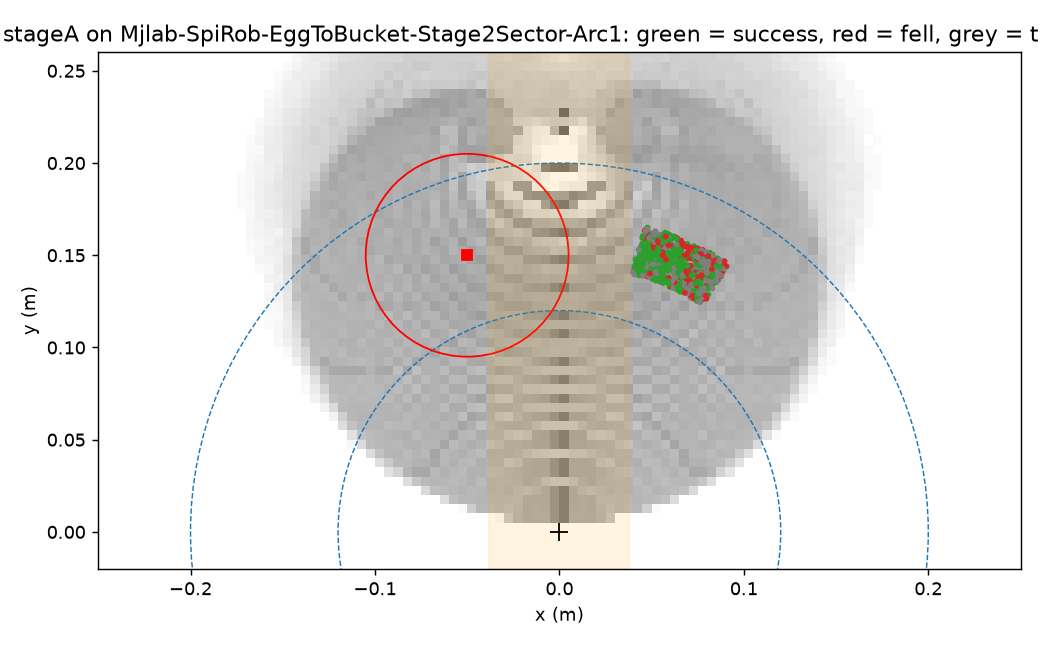

    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
  (obs_normalizer): EmpiricalNormalization()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
round 1/2: 414s, success 36%
round 2/2: 419s, success 27%
stageA on Mjlab-SpiRob-Polar-Wide
  nominal  : success   93%  fell    0%  (n=98)
  retention: success   76%  fell   10%  (n=239)
  sector   : success    7%  fell   33%  (n=687)
  sector spawns by angle:
  theta (deg) |   n  | success | fell
    30- 40   |   98 |     0%  |   5%
    40- 50   |  104 |     0%  |  75%
    50- 60   |  104 |     8%  |  73%
    60- 70   |   93 |    29%  |  32%
    70- 80   |   60 |    27%  |  10%
   120-130   |   38 |     0%  |  34%
   130-140 

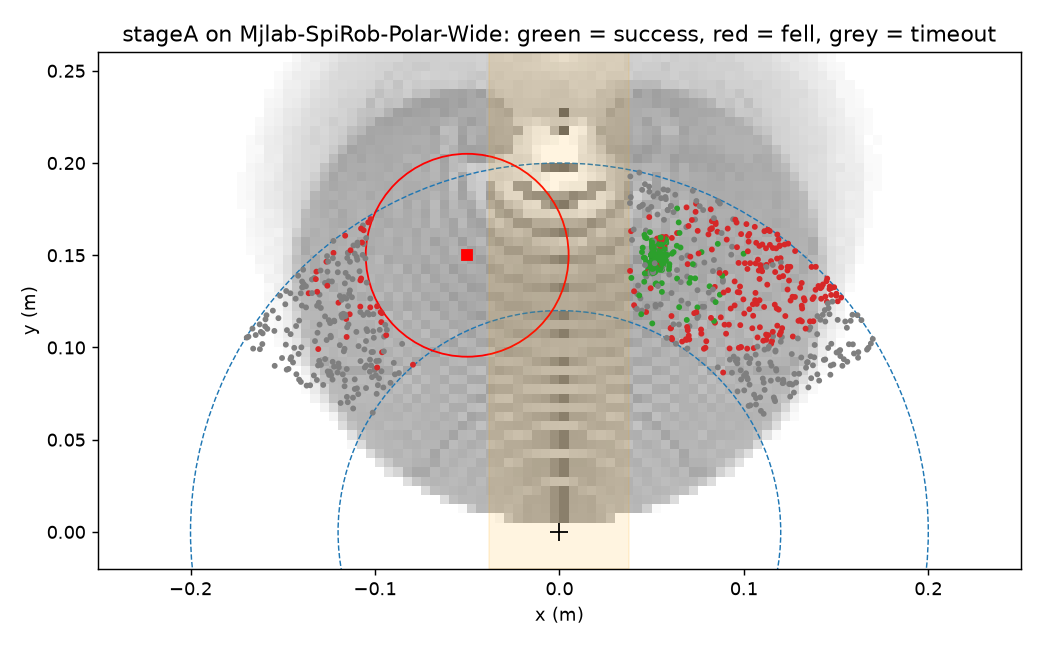

In [ ]:
CKPT_A = last_ckpt("stageA"); print("evaluating", CKPT_A)
evaluate(CKPT_A, "Mjlab-SpiRob-EggToBucket-Stage2Sector-Arc1", "stageA")
evaluate(CKPT_A, "Mjlab-SpiRob-Polar-Wide", "stageA")



## 5. Stage B: Arc-2 (44–77°, 133–186 mm)

In [ ]:
ITERS = 300
CKPT_B = run_stage("stageB", "Mjlab-SpiRob-EggToBucket-Stage2Sector-Arc2", last_ckpt("stageA"), ITERS)

evaluating /content/drive/MyDrive/spirob_vision/polar_teacher/stageB/model_299.pt
  (obs_normalizer): EmpiricalNormalization()
  (distribution): GaussianDistribution()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
  (obs_normalizer): EmpiricalNormalization()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
round 1/2: 414s, success 43%
round 2/2: 414s, success 44%
stageB on Mjlab-SpiRob-EggToBucket-Stage2Sector-Arc2
  nominal  : success   90%  fell    0%  (n=98)
  retention: success   73%  fell    8%  (n=329)
  sector   : success   20%  fell   55%  (n=597)
  sector spawns by angle:
  theta (

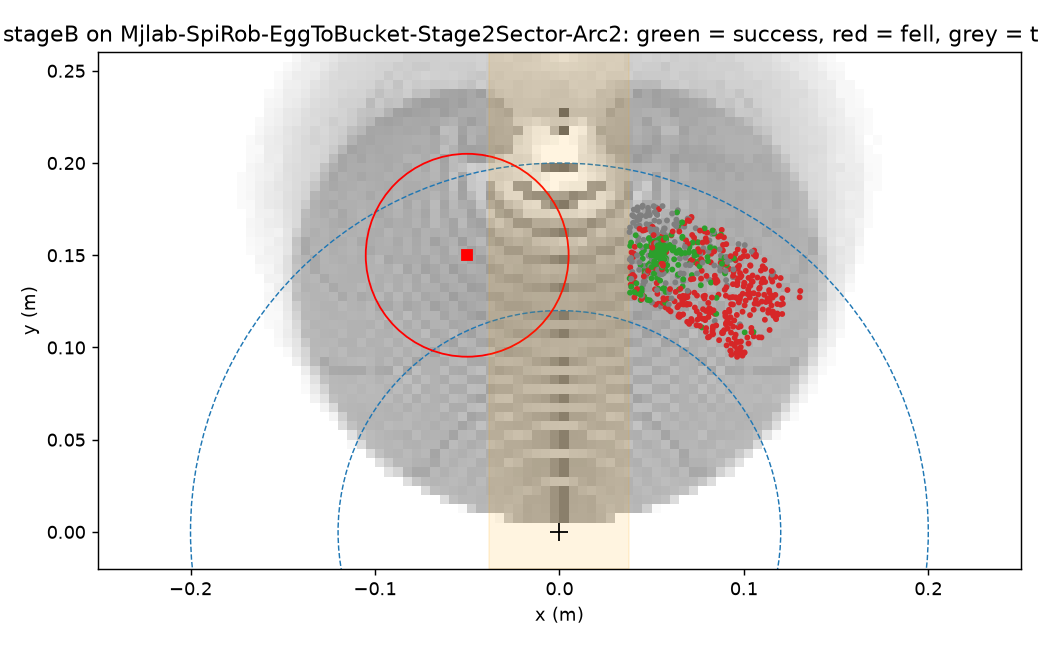

    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
  (obs_normalizer): EmpiricalNormalization()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
round 1/2: 416s, success 37%
round 2/2: 419s, success 29%
stageB on Mjlab-SpiRob-Polar-Wide
  nominal  : success   86%  fell    1%  (n=103)
  retention: success   79%  fell    3%  (n=251)
  sector   : success    7%  fell   50%  (n=670)
  sector spawns by angle:
  theta (deg) |   n  | success | fell
    30- 40   |   84 |     0%  |  75%
    40- 50   |  112 |     0%  | 100%
    50- 60   |   94 |     7%  |  86%
    60- 70   |  105 |    30%  |  47%
    70- 80   |   54 |    13%  |   4%
   120-130   |   36 |     3%  |  33%
   130-140

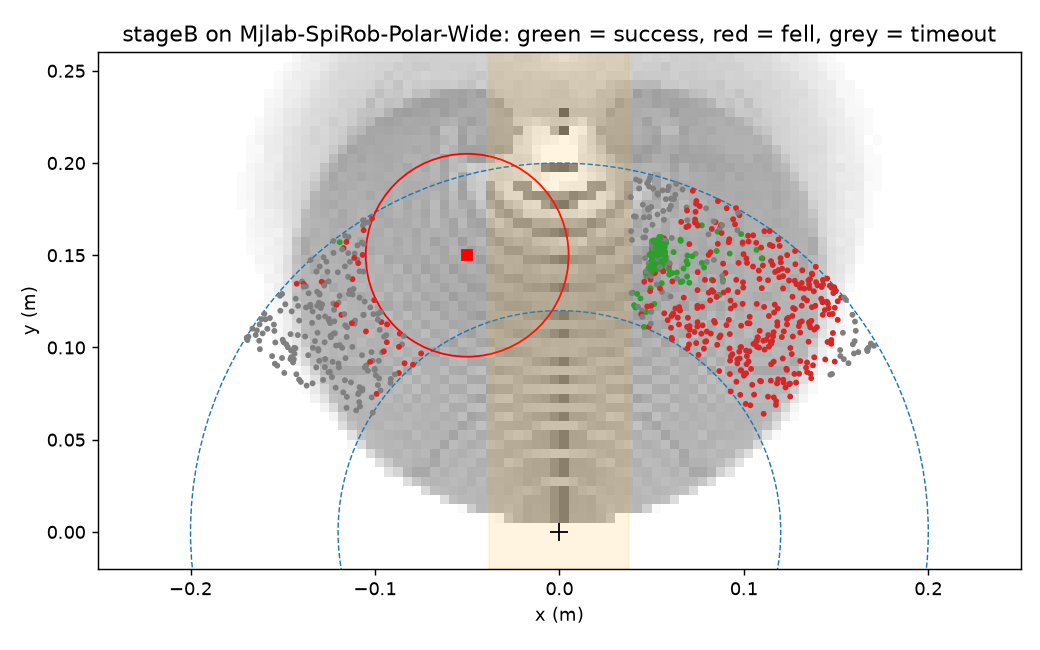

In [ ]:
CKPT_B = last_ckpt("stageB"); print("evaluating", CKPT_B)
evaluate(CKPT_B, "Mjlab-SpiRob-EggToBucket-Stage2Sector-Arc2", "stageB")
evaluate(CKPT_B, "Mjlab-SpiRob-Polar-Wide", "stageB")

  (obs_normalizer): EmpiricalNormalization()
  (distribution): GaussianDistribution()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
  (obs_normalizer): EmpiricalNormalization()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
round 1/2: 405s, success 41%
round 2/2: 405s, success 44%
stageA_on_Arc2 on Mjlab-SpiRob-EggToBucket-Stage2Sector-Arc2
  nominal  : success   93%  fell    0%  (n=109)
  retention: success   65%  fell   13%  (n=297)
  sector   : success   23%  fell   47%  (n=618)
  sector spawns by angle:
  theta (deg) |   n  | success | fell
    40- 50   |   81 |     0%  |  96%
    50-

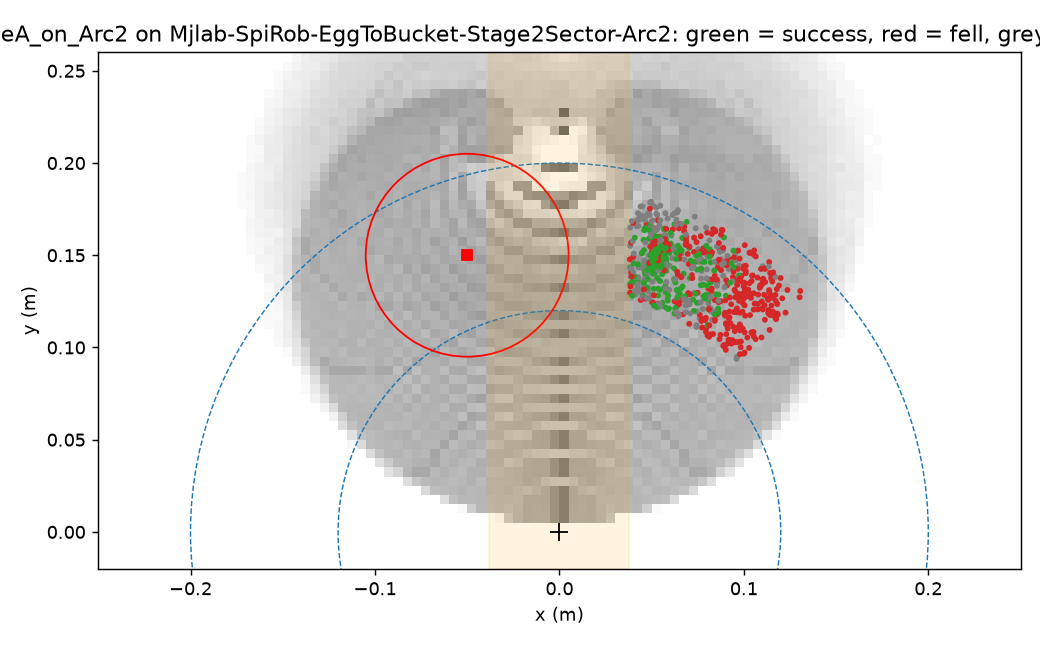

In [ ]:
evaluate(last_ckpt("stageA"), "Mjlab-SpiRob-EggToBucket-Stage2Sector-Arc2", "stageA_on_Arc2")

In [ ]:
!tail -60 /content/stageB.log | grep -E "Learning iteration|success_egg|egg_fell"

tail: cannot open '/content/stageB.log' for reading: No such file or directory


In [ ]:
extra = '''
register_mjlab_task(
    task_id="Mjlab-SpiRob-Polar-Arc15",
    env_cfg=polar_env_cfg((0.139, 0.179), (50.8, 75.8), play=False),
    play_env_cfg=polar_env_cfg((0.139, 0.179), (50.8, 75.8), play=True),
    rl_cfg=spirob_ppo_runner_cfg(stage2=True),
    runner_cls=Stage2FineTuneRunner,
)
POLAR_TASKS["Mjlab-SpiRob-Polar-Arc15"] = ((0.139, 0.179), (50.8, 75.8))
'''
p = f"{REPO}/tools/polar_tasks.py"
if "Polar-Arc15" not in open(p).read():
    open(p, "a").write(extra)
!cd {REPO} && uv run python -c "import sys; sys.path.insert(0,'tools'); import polar_tasks; print(list(polar_tasks.POLAR_TASKS))"

['Mjlab-SpiRob-Polar-Right', 'Mjlab-SpiRob-Polar-Left', 'Mjlab-SpiRob-Polar-Wide', 'Mjlab-SpiRob-Polar-Arc15']


In [ ]:
CKPT_A15 = run_stage("stageA15", "Mjlab-SpiRob-Polar-Arc15", last_ckpt("stageA"), 500)

evaluating /content/drive/MyDrive/spirob_vision/polar_teacher/stageA15/model_499.pt
     /root/.cache/warp/1.14.0
  (obs_normalizer): EmpiricalNormalization()
  (distribution): GaussianDistribution()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
  (obs_normalizer): EmpiricalNormalization()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
round 1/2: 405s, success 56%
round 2/2: 402s, success 52%
stageA15 on Mjlab-SpiRob-Polar-Arc15
  nominal  : success   69%  fell    1%  (n=100)
  retention: success   78%  fell    1%  (n=312)
  sector   : success   39%  fell   34%  (n=612)
  sector spawns by

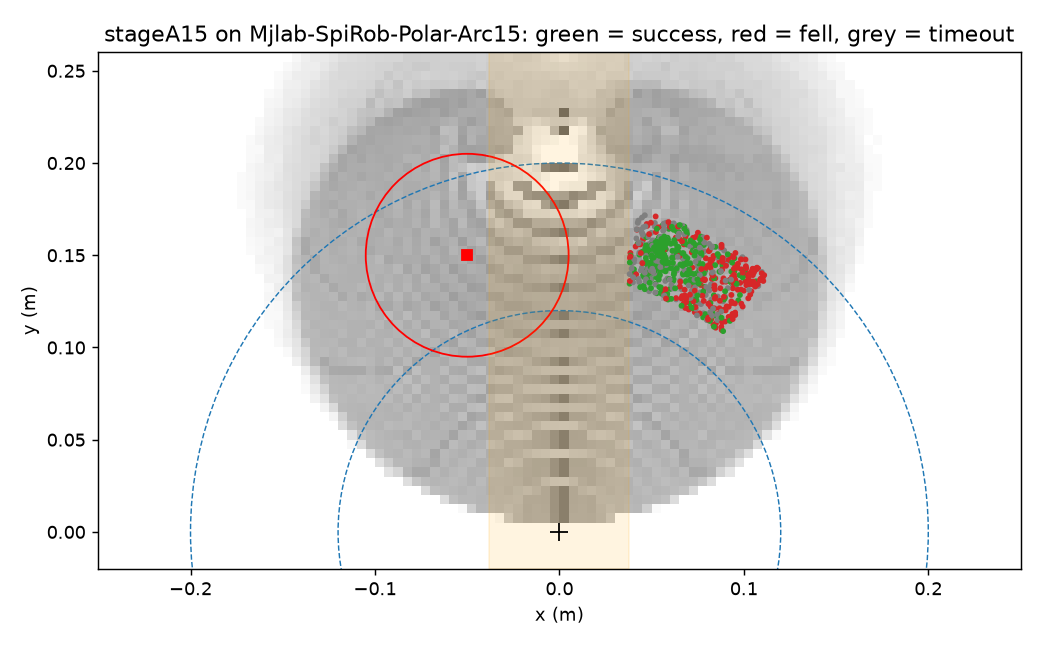

  (obs_normalizer): EmpiricalNormalization()
  (distribution): GaussianDistribution()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
  (obs_normalizer): EmpiricalNormalization()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
round 1/2: 409s, success 49%
round 2/2: 407s, success 56%
stageA15_on_Arc2 on Mjlab-SpiRob-EggToBucket-Stage2Sector-Arc2
  nominal  : success   77%  fell    0%  (n=116)
  retention: success   80%  fell    1%  (n=323)
  sector   : success   32%  fell   44%  (n=585)
  sector spawns by angle:
  theta (deg) |   n  | success | fell
    40- 50   |   78 |     3%  |  95%
    5

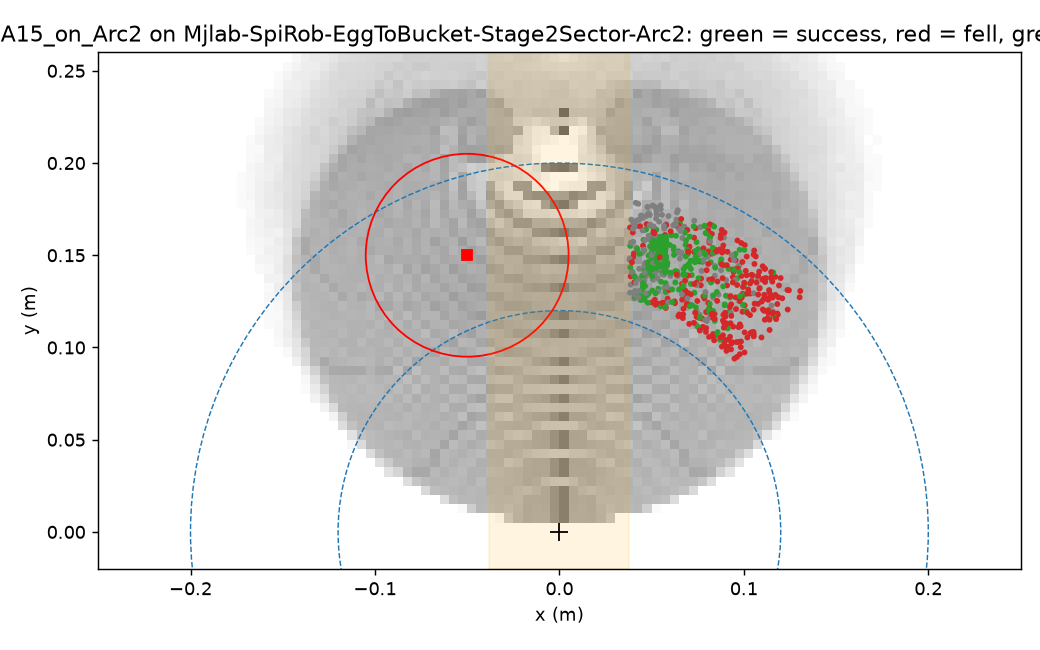

In [ ]:
CKPT_A15 = last_ckpt("stageA15"); print("evaluating", CKPT_A15)
evaluate(CKPT_A15, "Mjlab-SpiRob-Polar-Arc15", "stageA15")
evaluate(CKPT_A15, "Mjlab-SpiRob-EggToBucket-Stage2Sector-Arc2", "stageA15_on_Arc2")